# 3. Visualisation des données

In [5]:
import folium
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from branca.colormap import LinearColormap

export_path = "../reports/figures"

# Chargement du dataset
df = pd.read_csv("../data/weatherAUS.csv")
print("Données chargées avec succès.")
print("Dimensions du dataset :", df.shape)

# Transformation des variables binaires en numériques
df["RainToday"] = df["RainToday"].map({"No":0, "Yes":1})
df["RainTomorrow"] = df["RainTomorrow"].map({"No":0, "Yes":1})
df_numeric = df.select_dtypes(include=["number"])

Données chargées avec succès.
Dimensions du dataset : (145460, 23)


## 3.1 Corrélation entre les variables numériques

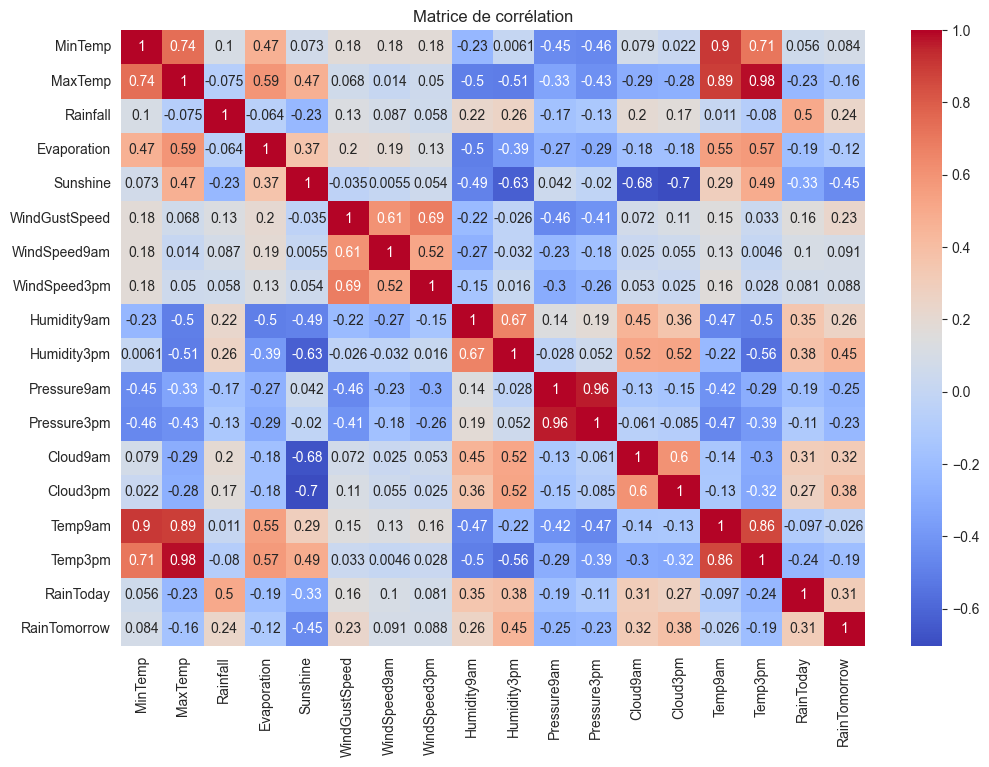

Corrélations positives (variables qui augmentent lorsque la probabilité de pluie augmente) : 
RainToday (0.31), Humidity3pm (0.45), Cloud3pm (0.38), Cloud9am (0.32), Humidity9am (0.26), Rainfall (0.24) et WindSpeed3pm (0.26).

Corrélations négatives (variables qui diminuent lorsque la probabilité de pluie augmente) : 
Sunshine (-0.45), Pressure3pm (-0.25), Pressure9am (-0.23), Temp3pm (-0.19) et MaxTemp (-0.16).

Corrélations quasi nulles (variables sans réelle relation linéaire avec la variable cible) : 
Temp9am (-0.02), MinTemp (-0.08), WindSpeed3pm (0.08) et WindSpeed9am (0.09).


In [6]:
# Matrice de corrélation
plt.figure(figsize=(12,8))
sns.heatmap(df_numeric.corr(), annot=True, cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

print("Corrélations positives (variables qui augmentent lorsque la probabilité de pluie augmente) : ")
print("RainToday (0.31), Humidity3pm (0.45), Cloud3pm (0.38), Cloud9am (0.32), Humidity9am (0.26), Rainfall (0.24) et WindSpeed3pm (0.26).")

print("\nCorrélations négatives (variables qui diminuent lorsque la probabilité de pluie augmente) : ")
print("Sunshine (-0.45), Pressure3pm (-0.25), Pressure9am (-0.23), Temp3pm (-0.19) et MaxTemp (-0.16).")

print("\nCorrélations quasi nulles (variables sans réelle relation linéaire avec la variable cible) : ")
print("Temp9am (-0.02), MinTemp (-0.08), WindSpeed3pm (0.08) et WindSpeed9am (0.09).")

### 3.1.1 Clustering Hiérarchique

### 3.1.2 Les valeurs nulles et la corrélation

## 3.2 Distribution de la variable cible

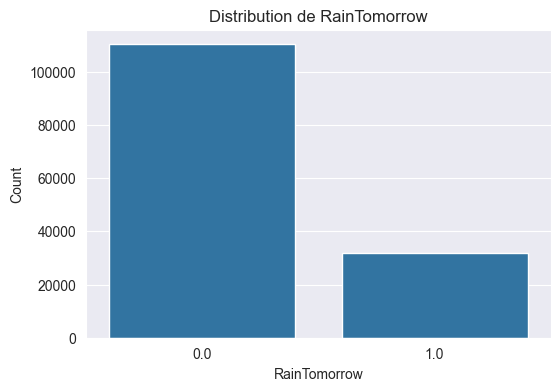

In [7]:
# Distribution de la variable cible
plt.figure(figsize=(6,4))
sns.countplot(x="RainTomorrow", data=df)
plt.title("Distribution de RainTomorrow")
plt.ylabel("Count")
plt.xlabel("RainTomorrow")
plt.show()

## 3.3 Distribution des variables numériques

## 3.4 Disparités de précipitations entre les villes

## 3.5 Distribution spatiale et analyse géographique

In [8]:
# Coordonnées géographiques des stations météorologiques
def get_location_coords():
    return {
        'Albury': (-36.0737, 146.9135),
        'BadgerysCreek': (-33.8817, 150.7443),
        'Cobar': (-31.4949, 145.8402),
        'CoffsHarbour': (-30.2963, 153.1135),
        'Moree': (-29.4658, 149.8407),
        'Newcastle': (-32.9283, 151.7817),
        'NorahHead': (-33.2817, 151.5677),
        'NorfolkIsland': (-29.0333, 167.9500),
        'Penrith': (-33.7507, 150.6942),
        'Richmond': (-33.5996, 150.7515),
        'Sydney': (-33.8688, 151.2093),
        'SydneyAirport': (-33.9399, 151.1753),
        'WaggaWagga': (-35.1082, 147.3598),
        'Williamtown': (-32.7932, 151.8360),
        'Wollongong': (-34.4278, 150.8931),
        'Canberra': (-35.2809, 149.1300),
        'Tuggeranong': (-35.4244, 149.0888),
        'MountGinini': (-35.5294, 148.7723),
        'Ballarat': (-37.5622, 143.8503),
        'Bendigo': (-36.7570, 144.2794),
        'Sale': (-38.1026, 147.0657),
        'MelbourneAirport': (-37.6690, 144.8410),
        'Melbourne': (-37.8136, 144.9631),
        'Mildura': (-34.2080, 142.1246),
        'Nhil': (-36.3328, 141.6503),
        'Portland': (-38.3463, 141.6042),
        'Watsonia': (-37.7121, 145.0827),
        'Dartmoor': (-37.9144, 141.2730),
        'Brisbane': (-27.4705, 153.0260),
        'Cairns': (-16.9186, 145.7781),
        'GoldCoast': (-28.0167, 153.4000),
        'Townsville': (-19.2590, 146.8169),
        'Adelaide': (-34.9285, 138.6007),
        'MountGambier': (-37.8284, 140.7804),
        'Nuriootpa': (-34.4693, 138.9973),
        'Woomera': (-31.1998, 136.8254),
        'Albany': (-35.0275, 117.8840),
        'Witchcliffe': (-34.0261, 115.1005),
        'PearceRAAF': (-31.6676, 116.0290),
        'PerthAirport': (-31.9403, 115.9668),
        'Perth': (-31.9505, 115.8605),
        'SalmonGums': (-32.9815, 121.6438),
        'Walpole': (-34.9777, 116.7338),
        'Hobart': (-42.8821, 147.3272),
        'Launceston': (-41.4332, 147.1441),
        'AliceSprings': (-23.6980, 133.8807),
        'Darwin': (-12.4634, 130.8456),
        'Katherine': (-14.4652, 132.2635),
        'Uluru': (-25.3444, 131.0369)
    }

In [9]:
# Cartographie des extrémités 


In [10]:
# Cartographie des valeurs manquantes
def generate_location_column_nan_map(df, column):
    location_coords = get_location_coords()
    
    # Create a base map centered on Australia
    m = folium.Map(location=[-28.2744, 133.7751], zoom_start=5, tiles="CartoDB Voyager")
    # colormap = LinearColormap(['green', 'yellow', 'orange', 'red'], vmin=0, vmax=100)
    # colormap.caption = f"Pourcentage de valeurs nulles ({column}) > 80%"
    # colormap.add_to(m)
    
    # Add a legend for the color coding with text center horizontal and vertical
    legend_html = '''
     <div style="
        position: fixed;
        bottom: 50px; left: 50px; width: 200px; height: 90px;
        border:2px solid grey; z-index:9999; font-size:14px;
        background-color:white;
        text-align: center;
        padding: 10px;
    ">
        &nbsp;<b>Légende</b><br>
        &nbsp;<i class="fa fa-circle" style="color:grey"></i>&nbsp;< 80% NaN<br>
        &nbsp;<i class="fa fa-circle" style="color:black"></i>&nbsp;> 80% NaN
     </div>
     '''
    m.get_root().html.add_child(folium.Element(legend_html))

    # Calculate the percentage of NaN values in the specified column for each location
    location_nan_percentage = df.groupby("Location")[column].apply(lambda x: x.isna().mean() * 100)
    # location_nan_percentage = location_nan_percentage[location_nan_percentage > 80]

    # Add markers for each location
    for location, percentage in location_nan_percentage.items():
        if location in location_coords:
            coords = location_coords[location]
            
            if percentage > 80:
                color = "black"
            else:
                color = "grey"
            
            folium.CircleMarker(
                location=coords,
                radius=10,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.7,
                popup=folium.Popup(f"{location}: {percentage:.2f}% NaN", max_width=200),
                tooltip=f"{location}: {percentage:.2f}% NaN"
            ).add_to(m)

    # Save the map as an HTML file
    m.save(f"{export_path}/location_{column.lower()}_nan_map.html")

def generate_location_fully_missing_variables_map(df):
    location_coords = get_location_coords()
    
    feature_cols = [
        "MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine",
        "WindGustDir", "WindGustSpeed", "WindDir9am", "WindDir3pm",
        "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm",
        "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm",
        "Temp9am", "Temp3pm"
    ]
    
    m = folium.Map(location=[-28.2744, 133.7751], zoom_start=5, tiles="CartoDB Voyager")
    
    legend_html = '''
     <div style="
        position: fixed;
        bottom: 50px; left: 50px; width: 260px; height: 100px;
        border:2px solid grey; z-index:9999; font-size:14px;
        background-color:white;
        text-align: left;
        padding: 10px;
    ">
        <b>Légende</b><br>
        <i class="fa fa-circle" style="color:orange"></i>&nbsp; 4 variables totalement absentes<br>
        <i class="fa fa-circle" style="color:red"></i>&nbsp; 6 variables totalement absentes
     </div>
     '''
    m.get_root().html.add_child(folium.Element(legend_html))

    for location, group in df.groupby("Location"):
        if location not in location_coords:
            continue
        
        fully_missing_vars = [col for col in feature_cols if group[col].isna().all()]
        n_fully_missing = len(fully_missing_vars)

        if n_fully_missing >= 6:
            color = "red"
        elif n_fully_missing >= 4:
            color = "orange"
        else:
            continue

        popup_text = f"""
        <b>{location}</b><br>
        Nombre de variables totalement absentes : {n_fully_missing}<br>
        <b>Variables concernées :</b><br>
        {'<br>'.join(fully_missing_vars) if fully_missing_vars else 'Aucune'}
        """

        folium.CircleMarker(
            location=location_coords[location],
            radius=10,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.7,
            popup=folium.Popup(popup_text, max_width=300),
            tooltip=f"{location}: {n_fully_missing} variable(s) absente(s)"
        ).add_to(m)

    m.save(f"{export_path}/location_fully_missing_variables_map.html")
    
generate_location_column_nan_map(df, "Sunshine")
generate_location_column_nan_map(df, "Evaporation")
generate_location_fully_missing_variables_map(df)
    
print("Exports de visualisations terminés.")
print(f"Visualisations enregistrées dans : {export_path}")

Exports de visualisations terminés.
Visualisations enregistrées dans : ../reports/figures


## 3.8 Analyse spatio-temporelle